# Is a particle image broken into pieces?

**A probe reports one size per image, the extent of everything shaded, so a 13-pixel drop with a 2-pixel speck 30 slices away is reported at 37 pixels, nearly three times its size.** In a synthetic population of 400 images, all 73 with such a speck are flagged and no clean drop is. The check labels connected pieces, joins those at most 8 empty pixels apart, and compares the largest group with the enclosing size: one labelling pass per image.

**What you get**

- the pieces, groups, enclosing size and largest-group size of each image, cross-checked against the package's `piece_groups`;
- how the gap setting trades rejoining broken particles against hiding specks;
- a cell that runs the check on your own decoded images and points each flag back at its row.

> **Every image in this notebook is synthetic**, drawn by hand and by a fixed-seed random-number generator in section 2; no data file is read.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [19_two_particles](19_two_particles.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

## 1. Why separated pieces inflate the size

The reported size is an extent: the image's length along the flight direction (slices), its width across
the array (diodes), or the smallest enclosing circle, depending on the size definition. Every one of these
grows with the distance between the outermost shaded pixels, whether or not they belong to the same
particle. A single stray pixel is enough, and nothing in the size variable says so.

## 2. Four synthetic frames

Rows are diodes, columns are slices. Each frame is 64 x 64 pixels:

- **compact drop**: a filled disc 12 pixels across;
- **drop + speck**: the same disc plus a 2-pixel speck 30 slices away;
- **split drop**: the same disc cut by one empty slice through its middle;
- **scattered pixels**: twelve isolated pixels and no particle.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 10, "legend.fontsize": 10, "axes.titlesize": 11})
from scipy import ndimage

N = 64
rng = np.random.default_rng(26)


def disc(cx, cy, d, n=N):
    yy, xx = np.mgrid[0:n, 0:n]
    return ((xx - cx) ** 2 + (yy - cy) ** 2) <= (d / 2.0) ** 2


compact = disc(16, 32, 12)

speck = compact.copy()
speck[40:42, 46] = True          # 2-pixel speck, 30 slices beyond the disc centre

split = compact.copy()
split[:, 16] = False             # one empty slice through the middle

scattered = np.zeros((N, N), bool)
idx = rng.choice(N * N, size=12, replace=False)
scattered.flat[idx] = True

frames = {
    "compact drop": compact,
    "drop + speck": speck,
    "split drop": split,
    "scattered pixels": scattered,
}
for k, v in frames.items():
    print(k, "shaded pixels:", int(v.sum()))

compact drop shaded pixels: 113
drop + speck shaded pixels: 115
split drop shaded pixels: 100
scattered pixels shaded pixels: 12


This cell defines a helper that draws a set of frames side by side on one pixel scale, then uses it to draw the four frames.

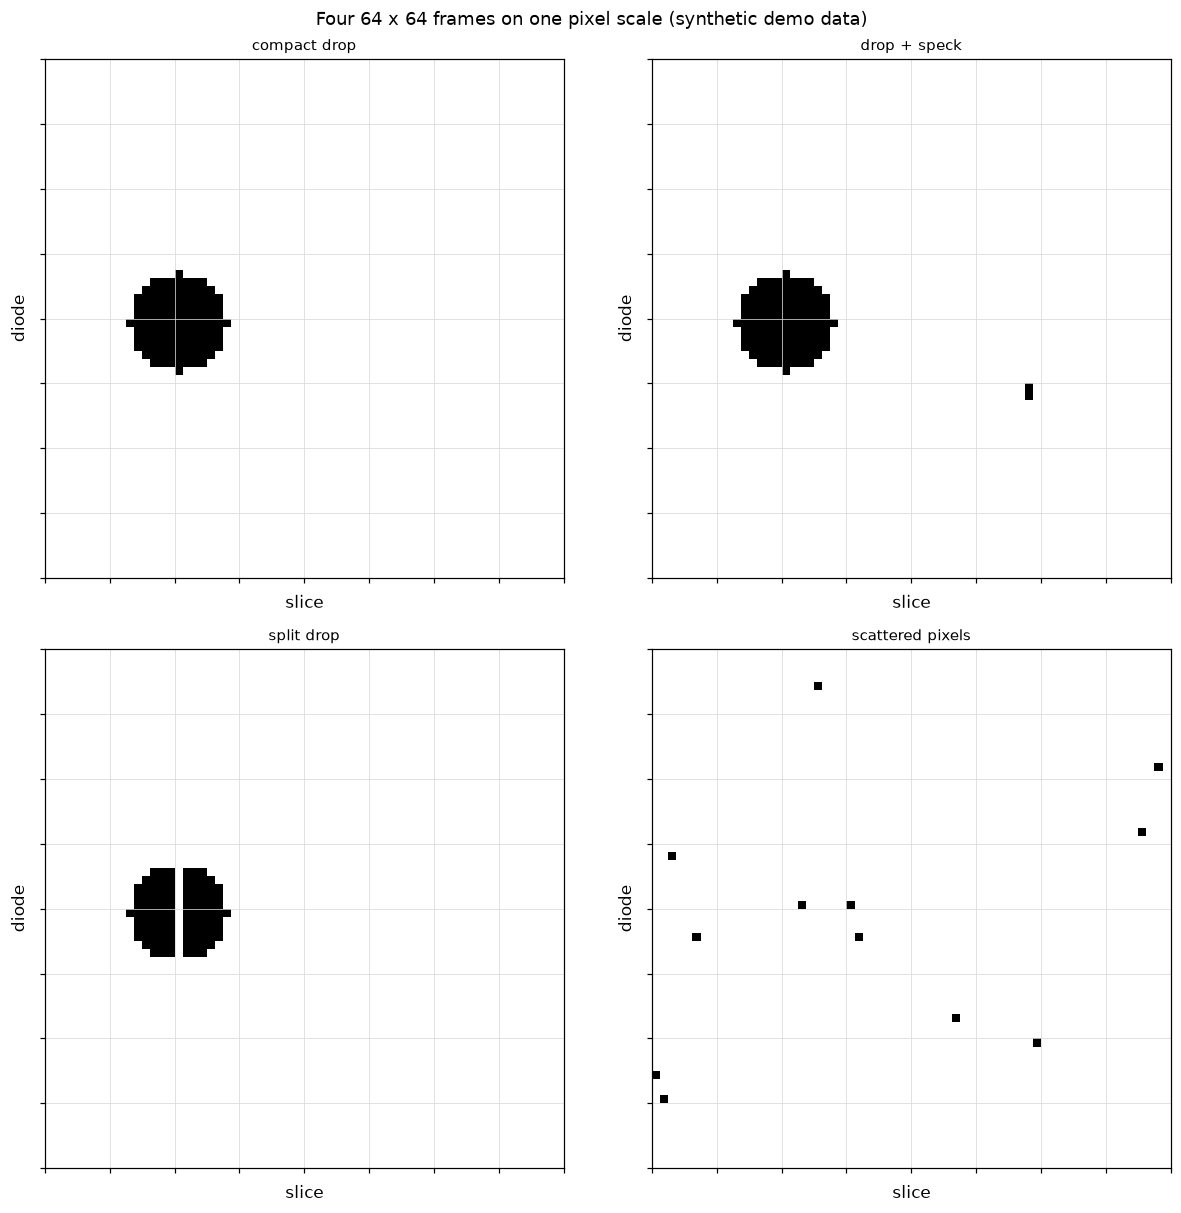

In [3]:
def show(frames, ncols=2, titles=None, suptitle="Four 64 x 64 frames on one pixel scale (synthetic demo data)"):
    names = list(frames)
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.6 * ncols, 5.6 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, k in zip(axes.flat, names):
        ax.axis("on")
        ax.imshow(frames[k], cmap="Greys", interpolation="nearest", vmin=0, vmax=1)
        ax.set_xticks(np.arange(-0.5, N, 8))
        ax.set_yticks(np.arange(-0.5, N, 8))
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.grid(color="0.85", lw=0.5)
        ax.set_xlabel("slice")
        ax.set_ylabel("diode")
        ax.set_title(titles[k] if titles else k, fontsize=10)
    fig.suptitle(suptitle, fontsize=12)
    fig.tight_layout()
    plt.show()


show(frames)

*Figure 1. The four synthetic frames: a compact drop, the same drop with a two-pixel speck, a drop split by one empty slice, and scattered pixels. Grid lines every 8 pixels.*

## 3. Pieces, the enclosing size and the largest piece

`ndimage.label` with a 3 x 3 structuring element finds the 8-connected pieces. Pieces are then grouped,
single linkage, when the number of empty pixels between their nearest pixels is at most `gap`: dilating every
pixel by a `(gap + 1)`-square makes two pixels touch exactly when that holds, so the labels of the dilated
image are the groups. The **enclosing size** is the larger bounding-box side of the whole image; the
**largest group's size** is the same measure on the biggest group alone.

In [4]:
GAP = 8           # empty pixels allowed between pieces of one particle (constant)
FLAG_RATIO = 2.0  # flag when the enclosing size exceeds the largest group's size by this factor


def extent(mask):
    rows, cols = np.nonzero(mask)
    if rows.size == 0:
        return 0
    return int(max(rows.max() - rows.min() + 1, cols.max() - cols.min() + 1))


def pieces(img):
    lab, n = ndimage.label(img, structure=np.ones((3, 3), int))
    return [lab == i for i in range(1, n + 1)]


def groups(img, gap=GAP):
    if gap <= 0:
        return pieces(img)
    grown = ndimage.binary_dilation(img, structure=np.ones((gap + 1, gap + 1), bool))
    lab, n = ndimage.label(grown, structure=np.ones((3, 3), int))
    out = [(lab == i) & img for i in range(1, n + 1)]
    return [g for g in out if g.any()]


def check(img, gap=GAP, ratio=FLAG_RATIO):
    gs = groups(img, gap)
    big = max(gs, key=extent) if gs else img
    enc, lg = extent(img), extent(big)
    return {"pieces": len(pieces(img)), "groups": len(gs), "enclosing": enc,
            "largest": lg, "flagged": bool(enc > ratio * max(lg, 1))}


print(f"{'frame':18s} pieces groups enclosing largest flagged")
for k, v in frames.items():
    r = check(v)
    print(f"{k:18s} {r['pieces']:6d} {r['groups']:6d} {r['enclosing']:9d} {r['largest']:7d} {r['flagged']}")

frame              pieces groups enclosing largest flagged
compact drop            1      1        13      13 False
drop + speck            2      2        37      13 True
split drop              2      1        13      13 False
scattered pixels       12      8        63       9 True


The compact drop is one piece and is not flagged. The split drop is two pieces one empty slice apart; the
8-pixel gap joins them, so its size is the drop's. The drop with a speck is reported at well over twice the
drop's size and is flagged. The scattered pixels have no piece larger than one pixel, so the enclosing size
is set entirely by the scatter.

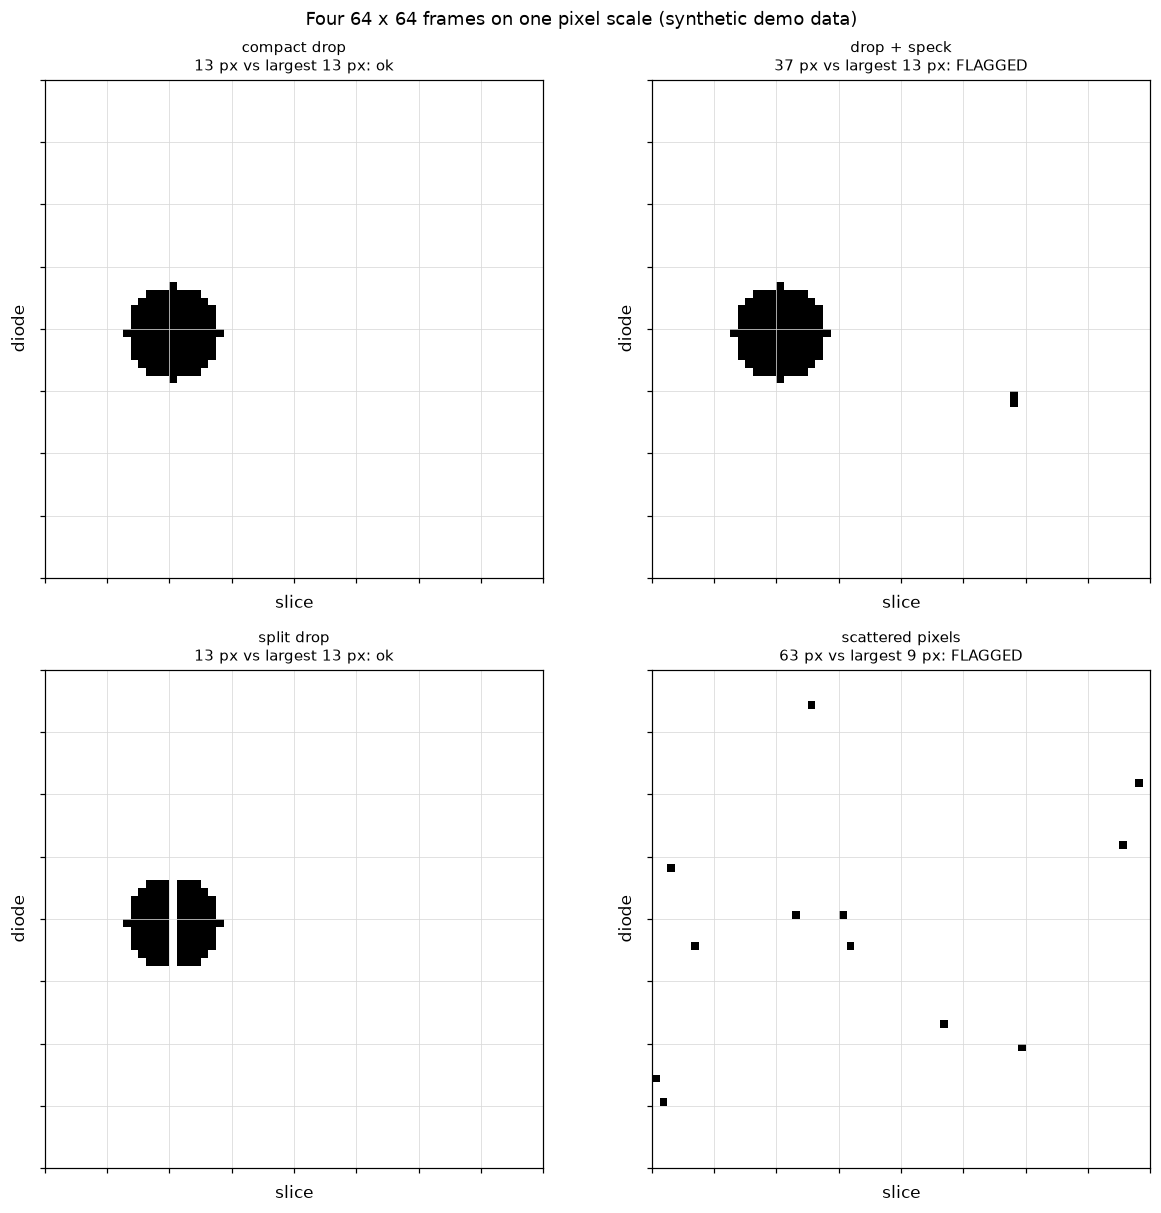

In [5]:
titles = {}
for k, v in frames.items():
    r = check(v)
    flag = "FLAGGED" if r["flagged"] else "ok"
    titles[k] = k + "\n" + str(r["enclosing"]) + " px vs largest " + str(r["largest"]) + " px: " + flag
show(frames, titles=titles)

*Figure 2. The same four frames, each titled with its piece count, enclosing size, largest piece and whether it is flagged.*

### Cross-check against the package

`arrayprobe.triage_context.piece_groups` implements the same grouping (8-connected pieces, single linkage
at most `gap` empty pixels apart). The cell below asserts it returns the same groups as the function above.

In [6]:
from arrayprobe.triage_context import piece_groups

for k, v in frames.items():
    for g in (0, 1, 8, 16):
        mine = sorted(int(m.sum()) for m in groups(v, g))
        theirs = sorted(int(np.asarray(m).sum()) for m in piece_groups(v, gap=g))
        assert mine == theirs, (k, g, mine, theirs)
print("groups agree with arrayprobe.triage_context.piece_groups for gaps 0, 1, 8 and 16")

groups agree with arrayprobe.triage_context.piece_groups for gaps 0, 1, 8 and 16


## 4. The gap rule, and what changing it does

The project's setting is a **constant gap of 8 pixels**: pieces with at most 8 empty pixels between them
are one particle. A smaller gap leaves broken particles as several pieces (the split drop at `gap = 0` is two pieces, not flagged because each half is nearly full size); a larger
gap swallows stray pixels into the particle and stops flagging them. The table and figure run the four
frames, and a fixed-seed population of 400 synthetic images, through gaps 0 to 32.

In [7]:
def make_population(n=400, seed=2603):
    r = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        img = disc(r.integers(14, 40), r.integers(14, 50), r.integers(6, 16))
        kind = str(r.choice(["clean", "speck", "split"], p=[0.6, 0.25, 0.15]))
        if kind == "speck":
            dist = int(r.integers(3, 24))
            x = min(N - 1, int(np.nonzero(img.any(0))[0].max()) + dist)
            img[int(r.integers(0, N)), x] = True
        elif kind == "split":
            cols = np.nonzero(img.any(0))[0]
            img[:, cols[len(cols) // 2]] = False
        out.append((kind, img))
    return out


population = make_population()
gaps = [0, 1, 2, 4, 8, 12, 16, 24, 32]
print("gap   " + "  ".join(f"{k[:10]:>10s}" for k in frames) + "   flagged of 400 (clean / speck / split)")
rates = []
for g in gaps:
    row = ["FLAG" if check(v, g)["flagged"] else "-" for v in frames.values()]
    by = {"clean": 0, "speck": 0, "split": 0}
    for kind, img in population:
        by[kind] += check(img, g)["flagged"]
    rates.append(by)
    print(f"{g:3d}   " + "  ".join(f"{s:>10s}" for s in row) + f"   {by['clean']:4d} / {by['speck']:4d} / {by['split']:4d}")

gap   compact dr  drop + spe  split drop  scattered    flagged of 400 (clean / speck / split)
  0            -        FLAG           -        FLAG      0 /   73 /    0
  1            -        FLAG           -        FLAG      0 /   73 /    0
  2            -        FLAG           -        FLAG      0 /   73 /    0
  4            -        FLAG           -        FLAG      0 /   73 /    0
  8            -        FLAG           -        FLAG      0 /   73 /    0
 12            -        FLAG           -           -      0 /   66 /    0
 16            -        FLAG           -           -      0 /   50 /    0
 24            -           -           -           -      0 /   20 /    0
 32            -           -           -           -      0 /    7 /    0


This cell plots the share of images flagged against the gap setting, for each of the three kinds of image in the population, with the project setting of 8 marked.

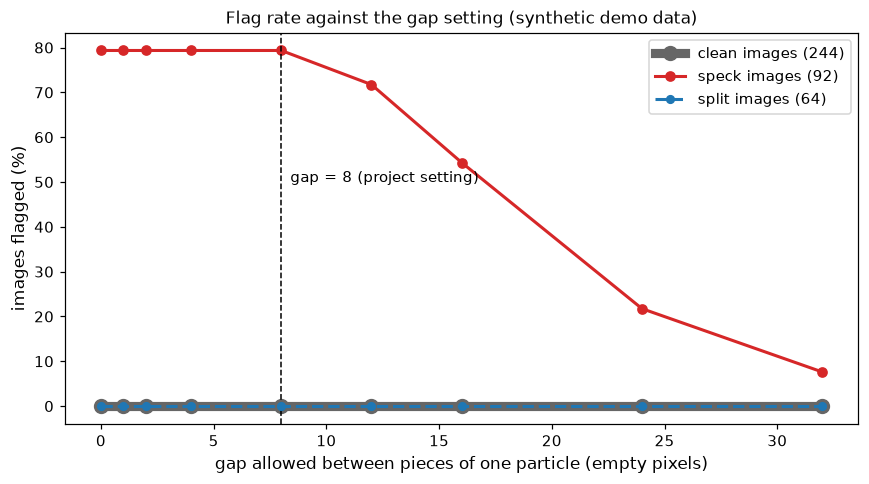

In [8]:
counts = {k: sum(1 for kk, _ in population if kk == k) for k in ("clean", "speck", "split")}
fig, ax = plt.subplots(figsize=(8, 4.5))
style = {"clean": dict(color="0.4", ls="-", lw=6, ms=9, zorder=1),
         "speck": dict(color="C3", ls="-", lw=2, ms=6, zorder=2),
         "split": dict(color="C0", ls="--", lw=2, ms=5, zorder=3)}
for k in ("clean", "speck", "split"):
    ax.plot(gaps, [100.0 * r[k] / counts[k] for r in rates], marker="o",
            label=k + " images (" + str(counts[k]) + ")", **style[k])
ax.axvline(GAP, color="k", ls="--", lw=1)
ax.text(GAP + 0.4, 50, "gap = 8 (project setting)", fontsize=10)
ax.set_xlabel("gap allowed between pieces of one particle (empty pixels)")
ax.set_ylabel("images flagged (%)")
ax.set_title("Flag rate against the gap setting (synthetic demo data)")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

*Figure 3. Percentage of each kind of synthetic image flagged as the allowed gap between pieces changes; the vertical dashed line marks the setting of 8 empty pixels. The clean (thick grey) and split (dashed blue) curves both sit at 0 % at every gap, so the dashed split curve is drawn on top of the clean one.*

Read the figure from the left. The flag compares the size of the whole image with the size of its largest group. A split drop is never
flagged here, at any gap: at `gap = 0` it is two pieces, but each half is nearly as large as the whole drop, so
the size ratio stays below 2. Specks stay flagged until the gap reaches their distance from the drop, so a large gap
hides them. Clean drops are never flagged. A constant 8 rejoins particles split by a few empty slices and
still flags a speck more than 8 pixels away; specks closer than that are counted as part of the particle,
which is the price of the setting.

## 5. Check your own data

**Counting pieces needs the decoded images**: the per-particle size variables in an image-processing (`proc`) file record only the enclosing size.

| variable | what it is |
|---|---|
| `image_length`, `image_width` | extent along the flight direction (slices) and across the array (diodes) |
| `image_diam_minR` | diameter of the smallest circle enclosing every shaded pixel (mm) |
| `image_diam_minR_uncorrected` | the size before the package's stray-pixel correction, where it ran (NaN when untouched) |

Replace the placeholder path and run the cell; it falls back to the synthetic population while the path does not exist. `load_images` returns a list of 2D boolean arrays (diodes x slices), one per particle, in the `proc` file's order, so a flagged index points back at that file's row.

In [9]:
IMAGES_FILE = Path("path/to/your/decoded_images.npz")  # placeholder: one 2D array per particle


def load_images(path):
    with np.load(path, allow_pickle=True) as z:
        return [np.asarray(a, bool) for a in z["images"]]


def check_your_own(images, gap=GAP, ratio=FLAG_RATIO, min_size=8):
    rows = []
    for i, img in enumerate(images):
        if extent(img) < min_size:
            continue
        r = check(img, gap, ratio)
        r["index"] = i
        rows.append(r)
    flagged = [r for r in rows if r["flagged"]]
    print(len(rows), "images at or above", min_size, "px;", len(flagged), "flagged at gap", gap)
    return flagged


if IMAGES_FILE.exists():
    images = load_images(IMAGES_FILE)
else:
    print("placeholder path not found: running on the synthetic population instead")
    images = [img for _, img in population]
my_flags = check_your_own(images)
for g in (0, 4, 16):
    check_your_own(images, gap=g)

placeholder path not found: running on the synthetic population instead
342 images at or above 8 px; 73 flagged at gap 8
342 images at or above 8 px; 73 flagged at gap 0
342 images at or above 8 px; 73 flagged at gap 4
342 images at or above 8 px; 50 flagged at gap 16


Look at a handful of flagged images before trusting a count: a flagged image whose largest piece is
itself the particle is a stray-pixel case; one whose pieces are all comparable is either a broken particle the
gap did not rejoin or two separate particles in one frame.

## 6. The package's correction

This notebook only finds the problem. [04_stray_pixel_images](04_stray_pixel_images.ipynb) shows the package's
stray-pixel correction and its uncorrected size kept beside it in `image_diam_minR_uncorrected`.